# Cooler stars keep better time

## Part 2: results

[Part 1](1_measuring_the_wander.ipynb) measured two numbers for each of 872 stars: its **wander** (how much its rotation period moves from one TESS sector to the next, as an angular speed in rad/day) and its **floor** (how much a perfectly steady star would seem to move in the same data). This notebook asks how they depend on temperature, checks the answer against the second sample and against independently made light curves, and compares it with a spot-evolution model.

Sections 1 to 6 are quick arithmetic on the tables in `results/`. Sections 7 and 8 need light curves and are cached the same way as in Part 1.

In [1]:
import sys
sys.path.insert(0, "..")

import csv
import json
import os
import time
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import wander as w
import spot_model as sm

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# False: read the saved results of sections 7 and 8. True: run them again from the light curves
# (run `python get_data.py` first; under a minute for section 7 and about 5 minutes for section 8).
RECOMPUTE = False

original = pd.read_csv(w.RESULTS / "stars_original.csv")
replication = pd.read_csv(w.RESULTS / "stars_replication.csv")
for table in (original, replication):
    table["slice"] = (table.teff // 200 * 200).astype(int)
samples = {"original": original, "replication": replication}
print(len(original), "original stars,", len(replication), "replication stars")

450 original stars, 422 replication stars


## 1. Wander and floor across temperature

Medians for each 200 K slice. The excess is the wander left after removing the floor in quadrature, `sqrt(wander² − floor²)`, under each of the two floors from Part 1 (shuffled = `white`, slid = `shifted`).

In [2]:
def slice_table(t):
    g = t.groupby("slice")
    return pd.DataFrame({
        "stars": g.size(),
        "wander": g.wander.median(),
        "floor_white": g.floor_white.median(),
        "floor_shifted": g.floor_shifted.median(),
        "excess_white": g.excess_white.median(),
        "excess_shifted": g.excess_shifted.median(),
    })

slices = {name: slice_table(t) for name, t in samples.items()}
print("original sample, median per slice (rad/day)")
slices["original"].round(4)

original sample, median per slice (rad/day)


,stars,wander,floor_white,floor_shifted,excess_white,excess_shifted
slice,,,,,,
3000,30,0.0141,0.0055,0.0096,0.0125,0.0104
3200,30,0.0106,0.0039,0.0082,0.0081,0.0041
3400,30,0.0114,0.0031,0.0081,0.0101,0.0069
3600,30,0.0121,0.0032,0.0068,0.0117,0.0088
3800,30,0.0099,0.0030,0.0066,0.0091,0.0074
4000,30,0.0129,0.0032,0.0075,0.0126,0.0086
4200,30,0.0116,0.0017,0.0062,0.0116,0.0106
4400,30,0.0157,0.0022,0.0078,0.0155,0.0144
4600,30,0.0177,0.0017,0.0073,0.0174,0.0149


original     shifted  floor: median excess 0.0304 (>= 5000 K, 150 stars) vs 0.0071 (< 3400 K, 60 stars) -> 4.3x
original     white    floor: median excess 0.0330 (>= 5000 K, 150 stars) vs 0.0102 (< 3400 K, 60 stars) -> 3.2x
replication  shifted  floor: median excess 0.0270 (>= 5000 K, 130 stars) vs 0.0072 (< 3400 K, 52 stars) -> 3.7x
replication  white    floor: median excess 0.0297 (>= 5000 K, 130 stars) vs 0.0107 (< 3400 K, 52 stars) -> 2.8x


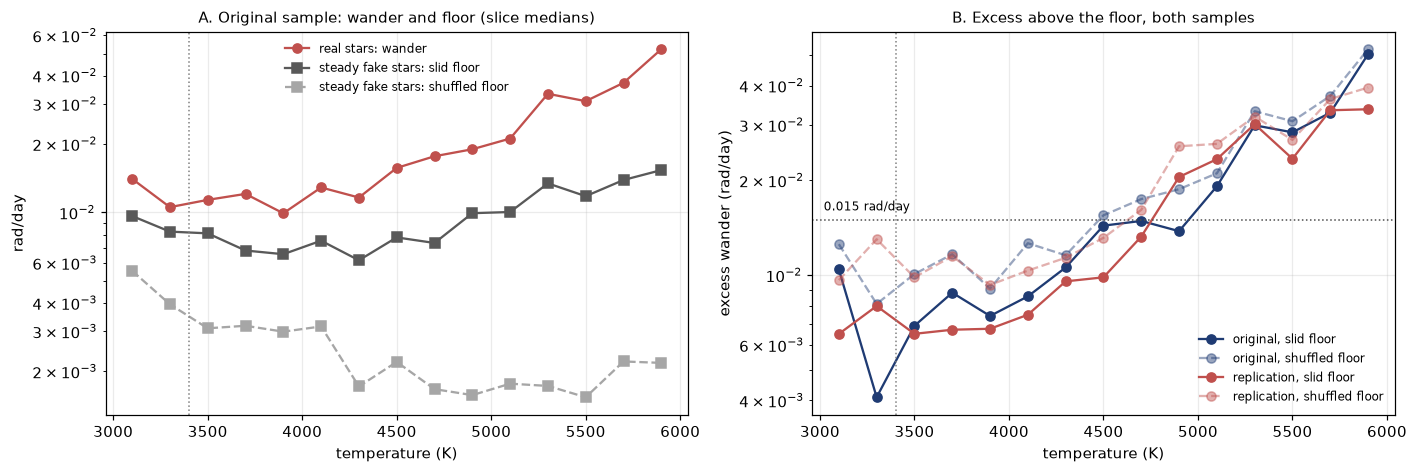

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
bt = slices["original"]
ax = axes[0]
ax.plot(bt.index + 100, bt.wander, "o-", color="#c0504d", label="real stars: wander")
ax.plot(bt.index + 100, bt.floor_shifted, "s-", color="0.35", label="steady fake stars: slid floor")
ax.plot(bt.index + 100, bt.floor_white, "s--", color="0.65", label="steady fake stars: shuffled floor")
ax.set_ylabel("rad/day")
ax.set_title("A. Original sample: wander and floor (slice medians)", fontsize=10)
ax.legend(fontsize=8, frameon=False)
ax = axes[1]
for name, color in [("original", "#1f3b73"), ("replication", "#c0504d")]:
    t = slices[name]
    ax.plot(t.index + 100, t.excess_shifted, "o-", color=color, label=f"{name}, slid floor")
    ax.plot(t.index + 100, t.excess_white, "o--", color=color, alpha=0.45, label=f"{name}, shuffled floor")
ax.axhline(w.FIXED_BAR, color="0.3", ls=":", lw=1)
ax.text(3020, w.FIXED_BAR * 1.07, "0.015 rad/day", fontsize=8)
ax.set_ylabel("excess wander (rad/day)")
ax.set_title("B. Excess above the floor, both samples", fontsize=10)
ax.legend(fontsize=8, frameon=False)
for ax in axes:
    ax.set_yscale("log")
    ax.set_xlabel("temperature (K)")
    ax.axvline(w.FULLY_CONVECTIVE_TEFF, color="0.5", ls=":", lw=1)
fig.tight_layout()
fig.savefig(w.FIGURES / "fig6_wander_vs_temperature.png", dpi=150)

for name, t in samples.items():
    hot, cool = t[t.teff >= 5000], t[t.teff < 3400]
    for floor in ("shifted", "white"):
        ratio = hot[f"excess_{floor}"].median() / cool[f"excess_{floor}"].median()
        print(f"{name:12s} {floor:8s} floor: median excess {hot[f'excess_{floor}'].median():.4f} (>= 5000 K, {len(hot)} stars) "
              f"vs {cool[f'excess_{floor}'].median():.4f} (< 3400 K, {len(cool)} stars) -> {ratio:.1f}x")

Three things stand out.

1. The wander of the real stars rises from about 0.01 rad/day in the M dwarfs to 0.03 to 0.05 rad/day in the hottest slices.
2. The floors do not follow it. The shuffled floor actually falls toward hotter stars, which in this sample are brighter and less noisy. The slid floor does rise, from about 0.007 rad/day in the middle slices to 0.012 to 0.015 in the hottest ones (probably because hot stars' leftovers contain more of their own changes within a month), but the wander rises much more. Neither floor can produce the trend.
3. With the slid floor removed, the Sun-like stars above 5,000 K have about four times the excess wander of the mid-M dwarfs below 3,400 K: 4.3× in the original sample and 3.7× in the replication. The replication (red) follows the original (blue) closely across the range. The biggest difference is in the 3,200 to 3,400 K slice, where the original's slid excess dips to 0.004 and the replication's stays near 0.008, so no single slice should be read too closely.

## 2. One fixed bar for every star: 0.015 rad/day

A median can hide what individual stars are doing, so here is a count instead. Draw one line at 0.015 rad/day of excess and count how many stars clear it, Sun-like (≥ 5,000 K) against mid-M dwarfs (< 3,400 K). The line is about twice the median slid floor of the coolest slices (0.008 to 0.010 rad/day) and well below the typical Sun-like excess.

In [4]:
def shares(t, floor, bar=w.FIXED_BAR):
    cool, hot = t[t.teff < 3400], t[t.teff >= 5000]
    return (cool[f"excess_{floor}"] > bar).mean(), (hot[f"excess_{floor}"] > bar).mean(), len(cool), len(hot)

rows = []
for name, t in samples.items():
    for floor in ("shifted", "white"):
        c, h, nc, nh = shares(t, floor)
        rows.append(dict(sample=name, floor=floor, sun_like_above=f"{100 * h:.0f}% of {nh}", mid_m_above=f"{100 * c:.0f}% of {nc}"))
pd.DataFrame(rows)

,sample,floor,sun_like_above,mid_m_above
0,original,shifted,83% of 150,18% of 60
1,original,white,88% of 150,22% of 60
2,replication,shifted,78% of 130,15% of 52
3,replication,white,88% of 130,25% of 52


In [5]:
rows = []
for bar in (0.010, 0.012, 0.015, 0.020, 0.025, 0.030):
    for name, t in samples.items():
        c, h, _, _ = shares(t, "shifted", bar)
        rows.append(dict(bar=bar, sample=name, sun_like=round(100 * h), mid_m=round(100 * c), ratio=round(h / c, 1)))
print("slid floor: % of stars above the bar, and the ratio Sun-like / mid-M")
pd.DataFrame(rows).pivot(index="bar", columns="sample", values=["sun_like", "mid_m", "ratio"])

slid floor: % of stars above the bar, and the ratio Sun-like / mid-M


sun_like                mid_m                ratio            
sample original replication original replication original replication
bar                                                                  
0.010      91.0        88.0     40.0        40.0      2.3         2.2
0.012      89.0        83.0     28.0        27.0      3.1         3.1
0.015      83.0        78.0     18.0        15.0      4.5         5.1
0.020      69.0        62.0     15.0         8.0      4.6         8.0
0.025      59.0        55.0     15.0         4.0      4.0        14.2
0.030      50.0        42.0      8.0         4.0      6.0        11.0

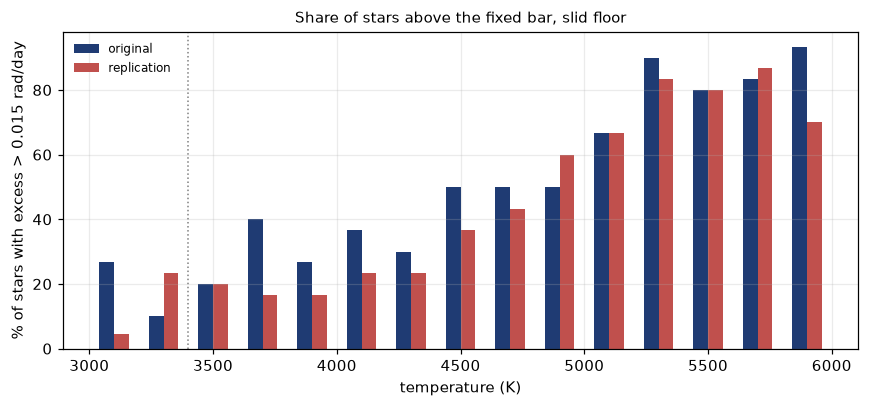

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for name, color, shift in [("original", "#1f3b73", -30), ("replication", "#c0504d", 30)]:
    t = samples[name]
    share = t.groupby("slice").excess_shifted.apply(lambda x: (x > w.FIXED_BAR).mean())
    ax.bar(share.index + 100 + shift, 100 * share, width=60, color=color, label=name)
ax.axvline(w.FULLY_CONVECTIVE_TEFF, color="0.5", ls=":", lw=1)
ax.set_xlabel("temperature (K)")
ax.set_ylabel("% of stars with excess > 0.015 rad/day")
ax.set_title("Share of stars above the fixed bar, slid floor", fontsize=10)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(w.FIGURES / "fig7_fixed_bar.png", dpi=150)

83% of the Sun-like stars clear the bar and 18% of the mid-M dwarfs (78% and 15% in the replication). Where exactly the line goes does not matter much: anywhere from 0.012 to 0.030 rad/day the Sun-like share is 3 to 6 times the M-dwarf share in the original sample, and 3 to 14 times in the replication.

## 3. The trend as one number, and a test for a jump at 3,400 K

A straight line through log₁₀(wander / floor) against temperature. Period, amplitude, brightness and number of sectors go into the same fit, so none of them can pass for a temperature effect (the cool stars are fainter, for example). The error bars are HC1 errors, which do not assume every star scatters around the line by the same amount.

To test the fully convective boundary, the fit is run again with one extra term: a step that switches on below 3,400 K. If fully convective stars behaved differently in a sudden way, the step would come out clearly different from zero.

In [7]:
def trend(t, floor):
    keep = t[np.isfinite(t[f"ratio_{floor}"]) & (t[f"ratio_{floor}"] > 0)]
    y = np.log10(keep[f"ratio_{floor}"].to_numpy())
    X, names = w.design_matrix(keep)
    coef, se = w.robust_fit(X, y)
    Xs, names_s = w.design_matrix(keep, with_step=True)
    coef_s, se_s = w.robust_fit(Xs, y)
    i, j = names.index("teff_per_1000K"), names_s.index("step_below_3400K")
    return dict(stars=len(keep), spearman_rho=stats.spearmanr(keep.teff, keep[f"ratio_{floor}"]).statistic,
                slope=coef[i], slope_se=se[i], slope_t=coef[i] / se[i],
                step=coef_s[j], step_se=se_s[j], step_t=coef_s[j] / se_s[j])

trend_table = pd.DataFrame([dict(sample=name, floor=floor, **trend(t, floor))
                            for name, t in samples.items() for floor in ("shifted", "white")])
print("slope in dex per 1,000 K (0.13 dex = a factor 1.35); step = extra jump below 3,400 K, in dex")
trend_table.round(3)

slope in dex per 1,000 K (0.13 dex = a factor 1.35); step = extra jump below 3,400 K, in dex


,sample,floor,stars,spearman_rho,slope,slope_se,slope_t,step,step_se,step_t
0,original,shifted,450,0.438,0.127,0.021,6.120,-0.005,0.042,-0.109
1,original,white,450,0.675,0.279,0.029,9.705,0.043,0.058,0.742
2,replication,shifted,422,0.432,0.109,0.023,4.771,0.037,0.037,1.007
3,replication,white,422,0.673,0.244,0.030,8.092,0.062,0.053,1.159


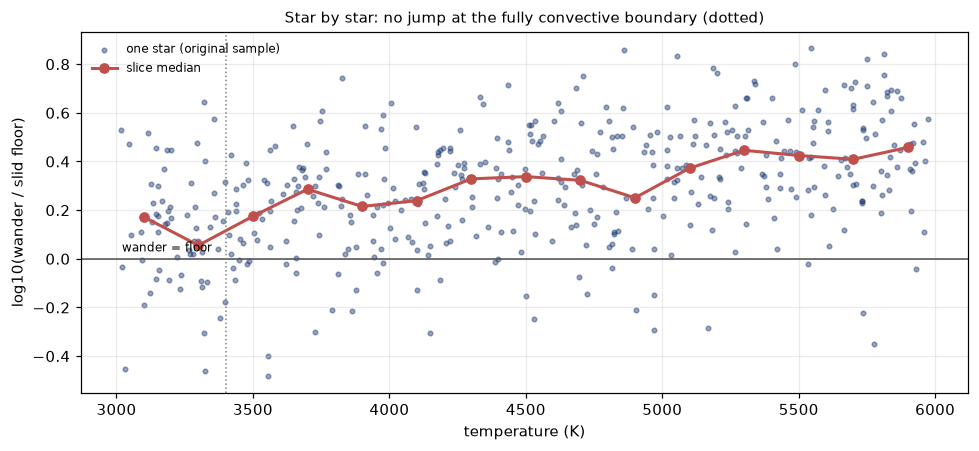

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.2))
t = original
y = np.log10(t.ratio_shifted.clip(lower=0.1))
ax.scatter(t.teff, y, s=9, color="#1f3b73", alpha=0.45, label="one star (original sample)")
med = t.assign(y=y).groupby("slice").y.median()
ax.plot(med.index + 100, med, "o-", color="#c0504d", lw=2, label="slice median")
ax.axhline(0, color="0.3", lw=1)
ax.text(3020, 0.03, "wander = floor", fontsize=8)
ax.axvline(w.FULLY_CONVECTIVE_TEFF, color="0.5", ls=":", lw=1)
ax.set_xlabel("temperature (K)")
ax.set_ylabel("log10(wander / slid floor)")
ax.set_title("Star by star: no jump at the fully convective boundary (dotted)", fontsize=10)
ax.legend(fontsize=8, frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(w.FIGURES / "fig8_per_star.png", dpi=150)

With the slid floor, the ratio rises by +0.127 ± 0.021 dex per 1,000 K (6.1σ) in the original sample and +0.109 ± 0.023 (4.8σ) in the replication. With the shuffled floor the slope is about twice as large (+0.28 and +0.24), so its size depends on the floor; its sign and significance do not.

The step below 3,400 K is −0.005 ± 0.042 dex (t = −0.1) in the original sample, and its t-value is between +0.7 and +1.2 in the other three runs. Nothing sudden happens at the boundary beyond the smooth trend. That is "no detectable step", not proof that there is none: only 60 stars in the original sample and 52 in the replication are below 3,400 K.

## 4. Does the wander depend on how fast the star spins?

Within three temperature groups, log₁₀(excess) against log₂(period), holding amplitude, brightness and sector count fixed. The slope is in dex per doubling of the period. Stars with zero excess are left out (the log is undefined).

In [9]:
groups = {"cool 3000-3800 K": (3000, 3800), "middle 3800-4800 K": (3800, 4800), "hot 4800-6000 K": (4800, 6000)}
period_table = pd.DataFrame([
    dict(sample=name, floor=floor, group=group, **w.period_slope(t[(t.teff >= lo) & (t.teff < hi)], floor))
    for name, t in samples.items() for floor in ("shifted", "white") for group, (lo, hi) in groups.items()
])
period_table.round(3)

,sample,floor,group,n,estimate,hc_se,t
0,original,shifted,cool 3000-3800 K,92,0.187,0.058,3.216
1,original,shifted,middle 3800-4800 K,136,0.134,0.043,3.131
2,original,shifted,hot 4800-6000 K,171,-0.032,0.048,-0.672
3,original,white,cool 3000-3800 K,112,0.182,0.044,4.095
4,original,white,middle 3800-4800 K,145,0.151,0.031,4.836
5,original,white,hot 4800-6000 K,180,0.042,0.043,0.980
6,replication,shifted,cool 3000-3800 K,86,0.102,0.053,1.950
7,replication,shifted,middle 3800-4800 K,127,0.095,0.041,2.338
8,replication,shifted,hot 4800-6000 K,149,0.024,0.058,0.419
9,replication,white,cool 3000-3800 K,104,0.177,0.046,3.879


In the cool group the excess grows with period in all four runs (+0.10 to +0.19 dex per doubling): slower M dwarfs wander more. In the hot group the slope is consistent with zero in all four. This is not in the conference abstract, but two of the replication predictions below are about it.

## 5. The replication, against predictions written beforehand

At 15:58 on 1 September, before the replication sample was drawn, three predictions were written down for it. They use the shuffled floor (the only one in use at that point) and come from the original sample's numbers:

1. **Trend**: slope between +0.20 and +0.35 dex per 1,000 K, with Spearman ρ(temperature, wander/floor) above 0.5. Original: +0.279, ρ = 0.675.
2. **Hot stars**: period slope in 4,800 to 6,000 K within ±0.10 dex per doubling. Original: +0.04.
3. **M dwarfs**: period slope in 3,000 to 3,800 K above +0.10 dex per doubling. Original: +0.18.

What each failure would have meant was fixed at the same time. If (1) failed, the abstract would say that the replication did not reproduce the slope. If (3) failed with a slope below +0.05, the statement about M-dwarf period dependence would be dropped. If (2) failed, so would the statement that hot stars show no period dependence.

In [10]:
rt = trend_table.query("sample == 'replication' and floor == 'white'").iloc[0]
rp = period_table.query("sample == 'replication' and floor == 'white'").set_index("group")
hot, cool = rp.loc["hot 4800-6000 K"], rp.loc["cool 3000-3800 K"]
predictions = pd.DataFrame([
    dict(prediction="1. slope +0.20 to +0.35, rho > 0.5", replication=f"{rt.slope:+.3f} ± {rt.slope_se:.3f}, rho = {rt.spearman_rho:.2f}",
         met=bool(0.20 <= rt.slope <= 0.35 and rt.spearman_rho > 0.5)),
    dict(prediction="2. hot period slope within ±0.10", replication=f"{hot.estimate:+.3f} ± {hot.hc_se:.3f}", met=bool(abs(hot.estimate) <= 0.10)),
    dict(prediction="3. cool period slope > +0.10", replication=f"{cool.estimate:+.3f} ± {cool.hc_se:.3f}", met=bool(cool.estimate > 0.10)),
])
predictions

,prediction,replication,met
0,"1. slope +0.20 to +0.35, rho > 0.5","+0.244 ± 0.030, rho = 0.67",True
1,2. hot period slope within ±0.10,+0.077 ± 0.051,True
2,3. cool period slope > +0.10,+0.177 ± 0.046,True


All three were met. With the slid floor (not part of the predictions, which were written before it existed) the replication gives a trend of +0.109 ± 0.023 dex per 1,000 K, an M-dwarf period slope of +0.10 ± 0.05 and a hot-star slope of +0.02 ± 0.06.

## 6. The same in the early and late mission?

TESS changed how often it records its full-frame images: every 30 minutes in sectors 1 to 26, every 10 minutes in 27 to 55, and every 200 seconds since. If the wander came from the instrument or the cadence, the wander in early sectors compared with late sectors should change with temperature. For every star with at least three sectors on each side, compare the wander in sectors 1 to 60 with the wander in sectors 61 and later (all 200-second data).

In [11]:
both = original[np.isfinite(original.early_wander) & np.isfinite(original.late_wander) & (original.late_wander > 0)]
early_late = np.log10(both.early_wander / both.late_wander)
r = stats.spearmanr(both.teff, early_late)
print(f"{len(both)} stars seen in both halves; median log10(early/late) = {early_late.median():+.3f}; "
      f"Spearman rho(temperature, early/late) = {r.statistic:+.3f}, p = {r.pvalue:.2f}")

390 stars seen in both halves; median log10(early/late) = +0.047; Spearman rho(temperature, early/late) = +0.040, p = 0.44


No relation with temperature (ρ = +0.04, p = 0.44). The trend is the same in both halves of the mission.

## 7. Is the wander in the star or in the TARS processing?

TARS is one team's way of turning TESS images into light curves. If the wander came from their processing, light curves made independently from the same images would not move the same way sector by sector. MIT's Quick-Look Pipeline (QLP) makes such light curves.

For 60 stars, the four in each 200 K slice with the most sectors in both pipelines (at least five), each shared sector was fit in TARS and in QLP with the same `fit_period`, and each sector's angular speed was compared with that star's median. If the deviations came from pipeline noise, they would not be correlated between the two. The star list is `data/qlp_check_stars.csv`.

The first attempt did not work. QLP's standard flux (`KSPSAP_FLUX`) is flattened for planet searches, and the flattening takes most of the rotation signal out. For one star checked by hand (TIC 347116630) the amplitudes came out at 0.0002 to 0.004, against 0.004 to 0.045 in TARS for the same sectors, and over all 60 stars the QLP wander came out a median 26 times the TARS wander. That run measured the flattening, not the stars. The comparison was redone on QLP's raw `SAP_FLUX`, with a quadratic removed from each spacecraft orbit and 5σ outliers clipped (`w.load_qlp_sector`).

In [12]:
qlp_csv = w.RESULTS / "qlp_sector_deviations.csv"
if qlp_csv.exists() and not RECOMPUTE:
    print(f"reading {qlp_csv.relative_to(w.ROOT)}")
    deviations = pd.read_csv(qlp_csv)
else:
    with (w.DATA / "qlp_check_stars.csv").open() as stream:
        check_stars = [dict(tic_id=int(r["tic_id"]), teff=float(r["teff"]), period=float(r["period"]),
                            overlap_sectors={int(s) for s in r["overlap_sectors"].split(",")}) for r in csv.DictReader(stream)]
    start = time.time()
    with ProcessPoolExecutor(max_workers=max(1, (os.cpu_count() or 2) - 2)) as pool:
        deviations = pd.DataFrame([row for rows in pool.map(w.compare_pipelines, check_stars) for row in rows])
    deviations.to_csv(qlp_csv, index=False)
    print(f"compared {deviations.tic_id.nunique()} stars in {time.time() - start:.0f} s")

pooled = stats.spearmanr(deviations.dev_tars, deviations.dev_qlp)
per_star = deviations.groupby("tic_id").apply(
    lambda d: pd.Series(dict(teff=d.teff.iloc[0], sectors=len(d), rho=stats.spearmanr(d.dev_tars, d.dev_qlp).statistic,
                             spread_tars=1.4826 * np.median(np.abs(d.dev_tars)))),
    include_groups=False)
print(f"{len(per_star)} stars, {len(deviations)} shared sectors; pooled Spearman rho = {pooled.statistic:.3f} "
      f"(p = {pooled.pvalue:.0e}); median per-star rho = {per_star.rho.median():.2f}; "
      f"{(per_star.rho > 0).sum()} of {len(per_star)} stars positive")
for name, group in per_star.groupby(per_star.teff < 4000):
    print(f"{'below' if name else 'above'} 4000 K: {len(group)} stars, median rho {group.rho.median():.2f}, "
          f"typical TARS deviation {group.spread_tars.median():.3f} rad/day")

reading results/qlp_sector_deviations.csv
60 stars, 660 shared sectors; pooled Spearman rho = 0.597 (p = 7e-65); median per-star rho = 0.60; 59 of 60 stars positive
above 4000 K: 40 stars, median rho 0.73, typical TARS deviation 0.023 rad/day
below 4000 K: 20 stars, median rho 0.26, typical TARS deviation 0.012 rad/day


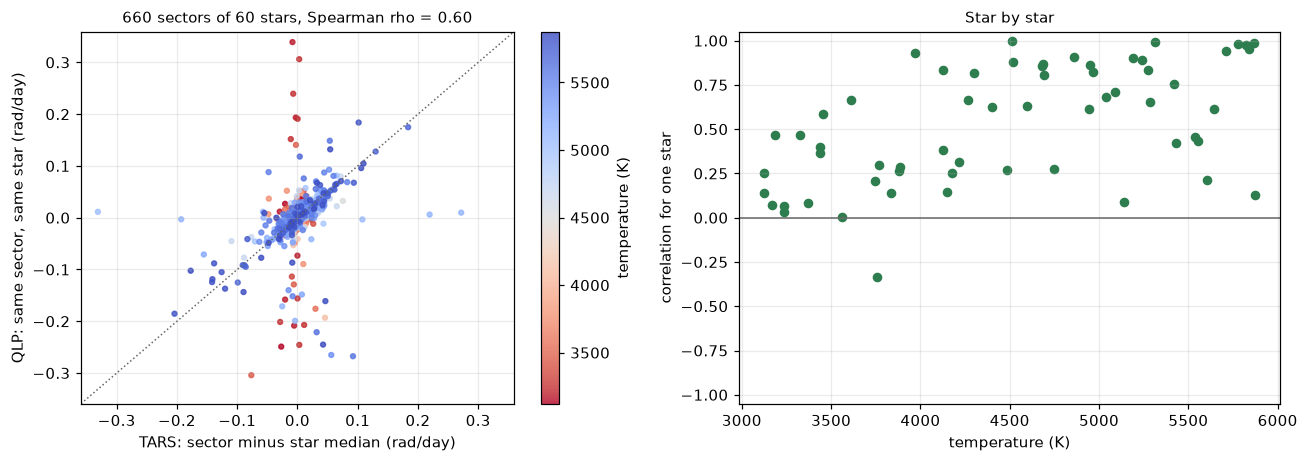

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
lim = np.nanpercentile(np.abs(np.r_[deviations.dev_tars, deviations.dev_qlp]), 99) * 1.1
points = axes[0].scatter(deviations.dev_tars, deviations.dev_qlp, s=10, c=deviations.teff, cmap="coolwarm_r", alpha=0.8)
axes[0].plot([-lim, lim], [-lim, lim], color="0.4", lw=1, ls=":")
axes[0].set_xlim(-lim, lim)
axes[0].set_ylim(-lim, lim)
axes[0].set_xlabel("TARS: sector minus star median (rad/day)")
axes[0].set_ylabel("QLP: same sector, same star (rad/day)")
axes[0].set_title(f"{len(deviations)} sectors of {len(per_star)} stars, Spearman rho = {pooled.statistic:.2f}", fontsize=10)
fig.colorbar(points, ax=axes[0], label="temperature (K)")
axes[1].scatter(per_star.teff, per_star.rho, s=28, color="#2e7d4f")
axes[1].axhline(0, color="0.4", lw=1)
axes[1].set_ylim(-1.05, 1.05)
axes[1].set_xlabel("temperature (K)")
axes[1].set_ylabel("correlation for one star")
axes[1].set_title("Star by star", fontsize=10)
fig.tight_layout()
fig.savefig(w.FIGURES / "fig9_tars_vs_qlp.png", dpi=150)

When TARS says a sector's rotation was unusually fast, QLP mostly says the same: ρ = 0.60 over 660 sectors, and 59 of the 60 stars have a positive correlation. Two independent reductions of the same images agree on the deviations, so they come from the star, not from the software.

The agreement is weakest for the stars below 4,000 K: median ρ = 0.26 for them against 0.73 for the hotter ones, and a few of their sectors (red points on the left) scatter far up or down in QLP while TARS stays near the median. That is what the main result would lead you to expect. Their sector-to-sector deviations are about half the size (0.012 against 0.023 rad/day), so the same measurement noise hides more of them.

## 8. What causes the wander? A spot-evolution model

Even if a star's rotation is steady on average, two things can make its measured period wander:

- **differential rotation (shear)**: spots at different latitudes go round at different speeds, so the period depends on where the spots are that month;
- **spot evolution**: spots grow, decay and change shape during a sector, which moves the periodogram peak.

To see how much each matters, `spot_model.py` makes fake spotted stars with Butterpy (Claytor et al. 2022) and measures them with the same code as the real stars. Each fake star copies one real star: its period, its TESS time stamps, its amplitude and its own leftover noise. Spot lifetimes come from the relation Giles, Collier Cameron & Haywood (2017) fit to Kepler stars. There are two versions, each run on the first 10 stars (by TIC number) in every slice, 150 stars in all:

- **rigid**: no differential rotation; spots emerge at 7° to 28° latitude, as on the Sun;
- **shear**: the Collier Cameron (2007) shear for the star's temperature, ΔΩ = 0.053 (T / 5130 K)^8.6 rad/day, with spots at 30° to 60°.

Every parameter was taken from the literature before the run and nothing was adjusted afterwards. The fake stars get a shuffled copy of the leftover as their noise, so the matching floor is the shuffled one; they are compared with the real stars' shuffled-floor excess for the same 150 stars.

In [14]:
model_csv = w.RESULTS / "spot_model.csv"
if model_csv.exists() and not RECOMPUTE:
    print(f"reading {model_csv.relative_to(w.ROOT)}")
    model = pd.read_csv(model_csv)
else:
    chosen = sm.model_stars(w.read_star_list("original_450"))
    jobs = [(row, shear_on) for shear_on in (False, True) for row in chosen]
    start = time.time()
    with ProcessPoolExecutor(max_workers=max(1, (os.cpu_count() or 2) - 2)) as pool:
        model = pd.DataFrame([r for r in pool.map(sm.run_one, jobs, chunksize=2) if r is not None])
    model.to_csv(model_csv, index=False)
    print(f"{len(model)} fake stars in {(time.time() - start) / 60:.1f} min")

observed = original.set_index("tic_id").excess_white
model["observed_excess"] = model.tic_id.map(observed)
model["slice"] = (model.teff // 200 * 200).astype(int)
bands = {"M dwarfs 3000-3800 K": (3000, 3800), "Sun-like 5000-6000 K": (5000, 6000)}
model_rows = []
for band, (lo, hi) in bands.items():
    for name in ("rigid", "shear"):
        m = model[(model.model == name) & (model.teff >= lo) & (model.teff < hi)]
        model_rows.append(dict(band=band, model=name, stars=len(m), model_excess=m.simulated_excess.median(),
                         observed_excess=m.observed_excess.median(),
                         model_over_observed=m.simulated_excess.median() / m.observed_excess.median()))
model_table = pd.DataFrame(model_rows).set_index(["band", "model"])
model_table.round(4)

reading results/spot_model.csv


stars  model_excess  observed_excess  model_over_observed
band                 model                                                           
M dwarfs 3000-3800 K rigid     40        0.0229           0.0094               2.4260
                     shear     40        0.0271           0.0094               2.8783
Sun-like 5000-6000 K rigid     50        0.0429           0.0410               1.0458
                     shear     50        0.0476           0.0410               1.1600

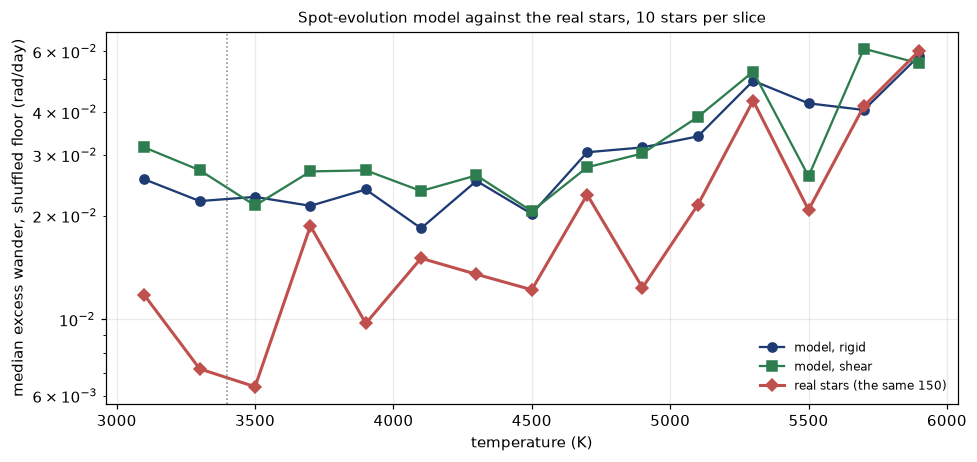

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.3))
for name, color, marker in [("rigid", "#1f3b73", "o"), ("shear", "#2e7d4f", "s")]:
    med = model[model.model == name].groupby("slice").simulated_excess.median()
    ax.plot(med.index + 100, med, marker + "-", color=color, label=f"model, {name}")
obs = model[model.model == "rigid"].groupby("slice").observed_excess.median()
ax.plot(obs.index + 100, obs, "D-", color="#c0504d", lw=2, label="real stars (the same 150)")
ax.axvline(w.FULLY_CONVECTIVE_TEFF, color="0.5", ls=":", lw=1)
ax.set_yscale("log")
ax.set_xlabel("temperature (K)")
ax.set_ylabel("median excess wander, shuffled floor (rad/day)")
ax.set_title("Spot-evolution model against the real stars, 10 stars per slice", fontsize=10)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(w.FIGURES / "fig10_spot_model.png", dpi=150)

For the Sun-like stars the rigid model lands on the observed wander (1.05 times it), and adding shear changes it only a little (1.16 times). Their wander is reproduced with or without shear: their spots evolve fast enough to explain it on their own.

For the M dwarfs the rigid model predicts 2.4 times the observed wander, and adding shear makes it worse (2.9 times). Real M dwarfs are steadier than spots with Kepler-calibrated lifetimes would make them.

So in the model, shear at the levels Doppler imaging finds barely changes the wander, and what sets it is how fast the spot pattern changes. M dwarfs' spot patterns stay the same for longer than the Giles relation, which was fit to hotter Kepler stars, predicts.

## 9. Check against the abstract

The conference abstract (`abstract.pdf`) was uploaded to the IFoRE submission form on 2 September 2026. `data/abstract_numbers.json` keeps the numbers behind it, taken from the analysis outputs of 1 and 2 September. The table recomputes each one from the files in this repository. "About four times" is the abstract's own wording, so that row only checks that the ratio rounds to 4.

In [16]:
recorded = json.load(open(w.DATA / "abstract_numbers.json"))
o_s, r_s = recorded["original_shifted"], recorded["replication_shifted"]
tt = trend_table.set_index(["sample", "floor"])
hot, cool = original[original.teff >= 5000], original[original.teff < 3400]
c_s, h_s, _, _ = shares(original, "shifted")
claims = [
    ("450 stars from 3,000 to 6,000 K", recorded["sample"]["original_stars"], len(original)),
    ("periods refitted in 4,317 sector light curves", recorded["sample"]["original_sectors"], int(original.sectors.sum())),
    ("Sun-like stars wandered about four times more", 4, hot.excess_shifted.median() / cool.excess_shifted.median()),
    ("83% of Sun-like stars above 0.015 rad/day", o_s["fraction_above_0p015_hot_ge_5000"], h_s),
    ("18% of mid-M dwarfs above 0.015 rad/day", o_s["fraction_above_0p015_cool_lt_3400"], c_s),
    ("no detectable jump at the boundary (step t)", o_s["step_indicator_3400K"]["t"], tt.loc[("original", "shifted"), "step_t"]),
    ("the trend itself, dex per 1,000 K", o_s["teff_coefficient_dex_per_1000K"]["estimate"], tt.loc[("original", "shifted"), "slope"]),
    ("422-star sample reproduced the trend (slope)", r_s["teff_coefficient_dex_per_1000K"]["estimate"], tt.loc[("replication", "shifted"), "slope"]),
    ("independent light curves: same deviations (rho)", recorded["independent_pipeline"]["pooled_spearman_rho"], pooled.statistic),
    ("model reproduces Sun-like wander, no shear", recorded["spot_model"]["rigid"]["sun_like_5000_6000K"]["simulated_over_observed"],
     model_table.loc[("Sun-like 5000-6000 K", "rigid"), "model_over_observed"]),
    ("model reproduces Sun-like wander, with shear", recorded["spot_model"]["shear"]["sun_like_5000_6000K"]["simulated_over_observed"],
     model_table.loc[("Sun-like 5000-6000 K", "shear"), "model_over_observed"]),
    ("model predicts 2.4 times too much for M dwarfs", recorded["spot_model"]["rigid"]["m_dwarfs_3000_3800K"]["simulated_over_observed"],
     model_table.loc[("M dwarfs 3000-3800 K", "rigid"), "model_over_observed"]),
]
check = pd.DataFrame(claims, columns=["claim", "recorded 2 Sep", "this notebook"])
check["same"] = np.isclose(check["recorded 2 Sep"].astype(float), check["this notebook"].astype(float), rtol=1e-6)
check.loc[2, "same"] = round(check.loc[2, "this notebook"]) == 4
check.to_csv(w.RESULTS / "abstract_check.csv", index=False)
print(f"{check.same.sum()} of {len(check)} numbers agree")
check.round(4)

12 of 12 numbers agree


,claim,recorded 2 Sep,this notebook,same
0,"450 stars from 3,000 to 6,000 K",450.0000,450.0000,True
1,"periods refitted in 4,317 sector light curves",4317.0000,4317.0000,True
2,Sun-like stars wandered about four times more,4.0000,4.2524,True
3,83% of Sun-like stars above 0.015 rad/day,0.8267,0.8267,True
4,18% of mid-M dwarfs above 0.015 rad/day,0.1833,0.1833,True
5,no detectable jump at the boundary (step t),-0.1094,-0.1094,True
6,"the trend itself, dex per 1,000 K",0.1270,0.1270,True
7,422-star sample reproduced the trend (slope),0.1089,0.1089,True
8,independent light curves: same deviations (rho),0.5967,0.5967,True
9,"model reproduces Sun-like wander, no shear",1.0458,1.0458,True


## 10. What this shows, and what it does not

**Shows.** After removing what noise alone would produce, the month-to-month wander of the rotation period falls about fourfold from Sun-like stars to mid-M dwarfs, and it does so smoothly: there is no detectable step at the fully convective boundary. The result held in a second sample of 422 stars against predictions written beforehand, and independently made light curves show the same sector-by-sector deviations. A spot-evolution model reproduces the Sun-like wander with or without shear and predicts 2.4 times too much for M dwarfs. The wander therefore tracks how fast a star's spot pattern changes more than its differential rotation. Cooler stars keep better time because their spot patterns stay coherent from month to month.

**Does not show.** That M dwarfs have less differential rotation: in the model the wander hardly responds to shear at the levels Doppler imaging measures, so this measurement cannot say much about shear either way. The size of the trend depends on the floor (+0.13 or +0.28 dex per 1,000 K), even though its direction and significance do not. Temperatures are the TARS catalogue values, so stars within a hundred kelvin or so of 3,400 K could sit on either side of the true boundary. The Giles lifetime relation was calibrated on hotter Kepler stars; measuring spot lifetimes directly in mid-M dwarfs would be the most direct test of the explanation.